# 04 · Task (c): penalty minutes (PIM)

**Goal:** for every player on a team's roster, predict how many penalty minutes (PIM) he will get in the regular season, the day before the season starts. Only data from earlier seasons is used; this season's games played are **not** known.

**Measure:** MAE, the average number of minutes off. Chosen because PIM is very skewed (a few "enforcers" get 200+ minutes): MAE is in minutes, easy to read, and not dominated by those few players. We also report Spearman (are players put in the right order?).

Same test as tasks (a) and (b): `evaluate_by_season` in `src/evaluation.py`, 9 test seasons 2000–2009, training only on earlier seasons.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, wilcoxon
from src.evaluation import evaluate_by_season, pim_mae, pick_with_practice_test
import warnings; warnings.filterwarnings("ignore")   # Spearman of a constant guess (the median) is undefined: shown as NaN

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
scoring = pd.read_csv("../hockey_development_data/Scoring.csv")
teams = pd.read_csv("../hockey_development_data/Teams.csv")
FIRST_YEAR = 1979

## 1. Player table: one row per player per NHL season

- A player traded during the season has one row per team (`stint`): we **sum** games, PIM and points over his stints, because we predict his season total.
- `pos` like "C/L" is reduced to the first letter (C, D, L, R or G).
- `team` = the team of his first stint (the roster he starts the season with, which is known before the season).
- Earlier seasons are kept to build the history columns, then the table starts in 1979, like tasks (a) and (b).

In [2]:
nhl = scoring[scoring["lgID"] == "NHL"].sort_values(["playerID", "year", "stint"])
players = nhl.groupby(["playerID", "year"], as_index=False).agg(
    GP=("GP", "sum"), PIM=("PIM", "sum"), Pts=("Pts", "sum"), pos=("pos", "first"), tmID=("tmID", "first"))
players["pos"] = players["pos"].str[0]
players = players.sort_values(["playerID", "year"]).reset_index(drop=True)
print(players.shape)
players.head()

(36822, 7)


,playerID,year,GP,PIM,Pts,pos,tmID
0,aaltoan01,1997,3.0,0.0,0.0,C,ANA
1,aaltoan01,1998,73.0,24.0,8.0,C,ANA
2,aaltoan01,1999,63.0,26.0,18.0,C,ANA
3,aaltoan01,2000,12.0,2.0,2.0,C,ANA
4,abbotge01,1943,1.0,0.0,0.0,G,BOS


## 2. Inputs, all known before the season

- **Last 3 seasons:** PIM, games and points of the player's previous 3 NHL seasons (`_1` = last season). 2005 follows 2003, because the table simply has no 2004.
- **League level:** penalties per game changed a lot (about 1.26 per game in 1986–92, 0.73 in 2004–09), so a player's PIM is also compared to the league rate of that season.
- **Marcel:** a classic sports forecast. Average the last 3 seasons with weights 5, 4, 3 (recent counts more), add 100 games of "league average" (so players with few games are pulled toward the average, instead of trusting a lucky or unlucky short season), and multiply by an expected number of games (half of last season's games + a tenth of the season before + 20).
- **Career rate:** all earlier PIM / all earlier games.
- **Seasons in the NHL** and **first season** (no earlier NHL season: 18% of rows).
- **Position** (one column per position).
- **Team style:** the team's PIM per game last season (some teams play rougher).

In [3]:
league_rate = players.groupby("year").apply(lambda g: g["PIM"].sum() / g["GP"].sum()).rename("league_rate")
players = players.join(league_rate, on="year")

g = players.groupby("playerID")
for k in [1, 2, 3]:
    for col in ["PIM", "GP", "Pts", "league_rate"]:
        players[f"{col}_{k}"] = g[col].shift(k)
players["seasons_before"] = g.cumcount()
players["career_rate"] = g["PIM"].transform(lambda x: x.shift(1).cumsum()) / g["GP"].transform(lambda x: x.shift(1).cumsum()).replace(0, np.nan)
players["rate_1"] = players["PIM_1"] / players["GP_1"].replace(0, np.nan)
players["pts_rate_1"] = players["Pts_1"] / players["GP_1"].replace(0, np.nan)
players["first_season"] = players["PIM_1"].isna().astype(int)

# Marcel: weighted last 3 seasons, compared to the league rate, pulled toward the league average
w = {1: 5, 2: 4, 3: 3}
weighted_pim = sum(w[k] * (players[f"PIM_{k}"] / players[f"league_rate_{k}"]).fillna(0) for k in w)
weighted_gp = sum(w[k] * players[f"GP_{k}"].fillna(0) for k in w)
players["marcel_rate_vs_league"] = (weighted_pim + 100) / (weighted_gp + 100)
players["games_guess"] = 0.5 * players["GP_1"].fillna(0) + 0.1 * players["GP_2"].fillna(0) + 20

# League rate of the previous season (this season's rate is not known yet)
prev_year = {y: p for p, y in zip(sorted(players["year"].unique())[:-1], sorted(players["year"].unique())[1:])}
players["league_rate_last"] = players["year"].map(lambda y: league_rate.get(prev_year.get(y)))

# Team style: the club's PIM per game last season
t = teams[teams["lgID"] == "NHL"][["year", "tmID", "franchID", "PIM", "G"]].sort_values(["franchID", "year"])
t["team_style_last"] = (t["PIM"] / t["G"]).groupby(t["franchID"]).shift(1)
players = players.merge(t[["year", "tmID", "team_style_last"]], on=["year", "tmID"], how="left")

for p in "CDLRG":
    players[f"pos_{p}"] = (players["pos"] == p).astype(int)

player_table = players[players["year"] >= FIRST_YEAR].reset_index(drop=True)
player_table.to_csv("../data/player_table.csv", index=False)
print(player_table.shape)
player_table[["PIM", "PIM_1", "GP_1", "marcel_rate_vs_league", "games_guess", "career_rate", "team_style_last"]].describe().round(2)

(24712, 34)


,PIM,PIM_1,GP_1,marcel_rate_vs_league,games_guess,career_rate,team_style_last
count,24712.00,20704.00,20704.00,24712.00,24712.00,20651.00,24235.00
mean,43.88,48.94,50.54,1.00,44.90,0.97,18.45
std,50.94,53.02,27.24,0.60,18.11,0.98,4.70
min,0.00,0.00,0.00,0.12,20.00,0.00,9.74
25%,6.00,10.00,27.00,0.63,24.30,0.36,14.73
50%,28.00,34.00,59.00,0.94,48.80,0.69,17.80
75%,62.00,68.00,75.00,1.07,62.20,1.22,21.62
max,409.00,409.00,86.00,6.03,71.00,21.00,33.91


## 3. A first look at the target

- How skewed is PIM, and how many players have 0?
- How much does a player's PIM carry over from one season to the next? (Spearman, because of the skew.)

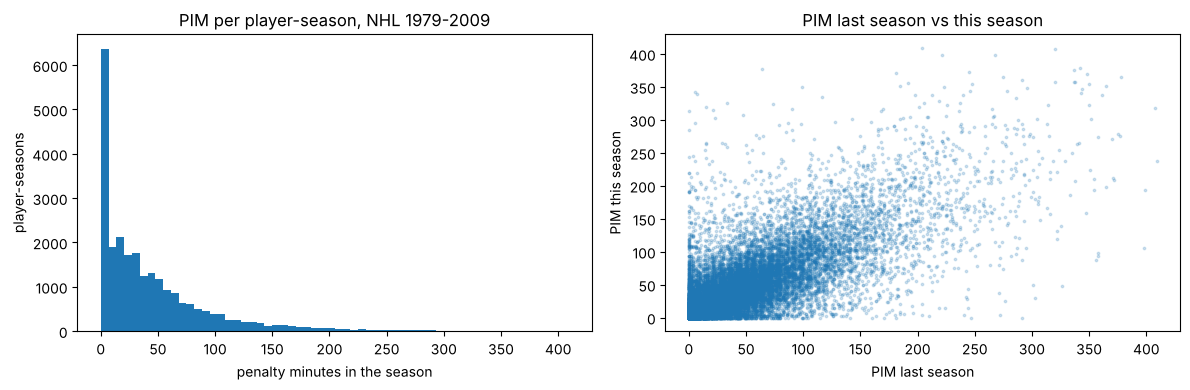

mean 43.9 | median 28.0 | share with 0: 0.12 | max 409.0
Spearman PIM last season vs this season: 0.71
share of players with no earlier NHL season: 0.16


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
player_table["PIM"].plot(kind="hist", bins=60, ax=axes[0], color="tab:blue")
axes[0].set(xlabel="penalty minutes in the season", ylabel="player-seasons", title="PIM per player-season, NHL 1979-2009")
both = player_table.dropna(subset=["PIM_1"])
axes[1].scatter(both["PIM_1"], both["PIM"], s=3, alpha=0.2)
axes[1].set(xlabel="PIM last season", ylabel="PIM this season", title="PIM last season vs this season")
plt.tight_layout(); plt.savefig(FIG / "pim_overview.png", dpi=150); plt.show()

print("mean", round(player_table["PIM"].mean(), 1), "| median", player_table["PIM"].median(),
      "| share with 0:", round((player_table["PIM"] == 0).mean(), 2), "| max", player_table["PIM"].max())
print("Spearman PIM last season vs this season:", round(spearmanr(both["PIM_1"], both["PIM"])[0], 2))
print("share of players with no earlier NHL season:", round(player_table["first_season"].mean(), 2))

## 4. Baselines (simple guesses to beat)

From no information to hockey knowledge:

1. **Median of the training seasons** for everyone.
2. **Average of the player's position** (defencemen and wingers get more penalties than goalies).
3. **Same as last season.**
4. **Marcel** (see section 2), turned back into minutes with last season's league rate.

Players in their first NHL season have no history: they get the median PIM of first-season players **of their position** in the training seasons (all baselines and models use the same rule, so the comparison is fair).

Ceiling (**not allowed**, only to show what is missing): last season's rate × this season's **real** games played.

In [5]:
seasons = [2000, 2001, 2002, 2003, 2005, 2006, 2007, 2008, 2009]

def first_season_fill(train, test):
    firsts = train[train["first_season"] == 1]
    return test["pos"].map(firsts.groupby("pos")["PIM"].median()).fillna(firsts["PIM"].median())

def median_guess(train, test):   return np.full(len(test), train["PIM"].median())
def position_mean(train, test):  return test["pos"].map(train.groupby("pos")["PIM"].mean()).fillna(train["PIM"].mean()).values
def same_as_last(train, test):   return test["PIM_1"].fillna(first_season_fill(train, test)).values
def marcel(train, test):
    guess = test["marcel_rate_vs_league"] * test["league_rate_last"] * test["games_guess"]
    return guess.where(test["first_season"] == 0, first_season_fill(train, test)).values
def ceiling_real_games(train, test):   # NOT allowed: uses this season's games
    return (test["rate_1"] * test["GP"]).fillna(first_season_fill(train, test)).values

def spearman(test, pred): return spearmanr(pred, test["PIM"])[0]

baselines = {"Median": median_guess, "Position average": position_mean, "Same as last season": same_as_last,
             "Marcel": marcel, "(not allowed) real games": ceiling_real_games}
results_c = {name: evaluate_by_season(player_table, f, pim_mae, seasons) for name, f in baselines.items()}
pd.DataFrame({name: {"MAE": round(r["score"].mean(), 2),
                     "Spearman": round(evaluate_by_season(player_table, baselines[name], spearman, seasons)["score"].mean(), 3)}
              for name, r in results_c.items()}).T

,MAE,Spearman
Median,27.30,NaN
Position average,28.98,0.275
Same as last season,18.37,0.711
Marcel,17.17,0.723
(not allowed) real games,13.97,0.833


## 5. Models

Four model types with different ways of learning, all with the same inputs:

- **Linear regression:** a weighted sum of the inputs.
- **Decision tree:** a chain of yes/no questions.
- **k-nearest neighbours:** copies the PIM of the most similar past players (inputs scaled first).
- **Gradient boosting:** many small trees, each fixing the previous ones' mistakes. We train it with **absolute error** as its loss, so it learns exactly what MAE measures (the median, not the average, which the few enforcers would pull up).

Missing history (first-season players, or fewer than 3 earlier seasons) is filled with −1 for the linear model, tree and kNN, plus the `first_season` flag; gradient boosting handles missing values itself. Settings are chosen with the practice test (last 3 training seasons). This cell takes a few minutes.

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEATURES_C = ["PIM_1", "PIM_2", "PIM_3", "GP_1", "GP_2", "GP_3", "rate_1", "career_rate", "marcel_rate_vs_league",
              "games_guess", "pts_rate_1", "seasons_before", "first_season", "pos_C", "pos_D", "pos_L", "pos_R", "pos_G",
              "team_style_last", "league_rate_last"]

def pim_model(make_model, fill_missing=True):
    def predict(train, test):
        X_train, X_test = train[FEATURES_C], test[FEATURES_C]
        if fill_missing:
            X_train, X_test = X_train.fillna(-1), X_test.fillna(-1)
        model = make_model().fit(X_train, train["PIM"])
        return np.clip(model.predict(X_test), 0, None)
    return predict

candidates_c = {
    "Linear": {"linear": pim_model(lambda: make_pipeline(StandardScaler(), LinearRegression()))},
    "Decision tree": {f"depth {d}": pim_model(lambda d=d: DecisionTreeRegressor(max_depth=d, min_samples_leaf=50,
                                                                                criterion="absolute_error", random_state=0))
                      for d in [4, 6, 8]},
    "k-nearest neighbours": {f"k = {k}": pim_model(lambda k=k: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)))
                             for k in [25, 100]},
    "Gradient boosting": {f"{lr} rate, {leaves} leaves": pim_model(lambda lr=lr, leaves=leaves: HistGradientBoostingRegressor(
                              loss="absolute_error", learning_rate=lr, max_leaf_nodes=leaves, max_iter=300,
                              min_samples_leaf=40, random_state=0), fill_missing=False)
                          for lr in [0.05, 0.1] for leaves in [7, 15]},
}

chosen_c = {}
def chosen_fairly_c(candidates, label):
    def predict(train, test):
        best, _ = pick_with_practice_test(train, candidates, pim_mae)
        chosen_c.setdefault(label, []).append(best)
        return candidates[best](train, test)
    return predict

for name, cands in candidates_c.items():
    results_c[name] = evaluate_by_season(player_table, chosen_fairly_c(cands, name), pim_mae, seasons)
print("done")

done


## 6. Comparison and checks

- **Better than Marcel:** in how many of the 9 seasons the model had a lower MAE than Marcel, our strongest allowed baseline.
- **Wilcoxon p:** chance a difference this big appears by luck. Below 0.05 counts as real.
- **Training error:** MAE of the last refit (trained on 1979–2008) on its own most recent training seasons, 2006–2008. We use recent seasons only, because the 1980s had many more penalties and therefore bigger errors, which would hide any memorising. Much lower than the test error = memorising (overfitting).

In [7]:
rows = {}
for name, r in results_c.items():
    row = {"MAE": round(r["score"].mean(), 2)}
    if name in candidates_c:
        row["better than Marcel"] = f'{(r["score"].values < results_c["Marcel"]["score"].values).sum()} / 9'
        row["Wilcoxon p vs Marcel"] = round(wilcoxon(r["score"], results_c["Marcel"]["score"]).pvalue, 3)
        best = pd.Series(chosen_c[name]).value_counts().index[0]
        train = player_table[player_table["year"] < seasons[-1]]
        recent = train[train["year"] >= 2006]
        row["training MAE (2006-08)"] = round(pim_mae(recent, candidates_c[name][best](train, recent)), 2)
        row["most chosen setting"] = best
    rows[name] = row
pd.DataFrame(rows).T.sort_values("MAE")

,MAE,better than Marcel,Wilcoxon p vs Marcel,training MAE (2006-08),most chosen setting
(not allowed) real games,13.97,NaN,NaN,NaN,NaN
Gradient boosting,16.54,9 / 9,0.004,15.44,"0.05 rate, 7 leaves"
Marcel,17.17,NaN,NaN,NaN,NaN
Decision tree,17.29,4 / 9,0.359,16.19,depth 4
Linear,17.62,0 / 9,0.004,16.65,linear
k-nearest neighbours,17.93,1 / 9,0.012,16.8,k = 100
Same as last season,18.37,NaN,NaN,NaN,NaN
Median,27.3,NaN,NaN,NaN,NaN
Position average,28.98,NaN,NaN,NaN,NaN


## 7. Which inputs matter (gradient boosting)

We scramble one input at a time in the last test season and measure how many minutes worse the MAE gets (5 scrambles each). Big = the model relies on it.

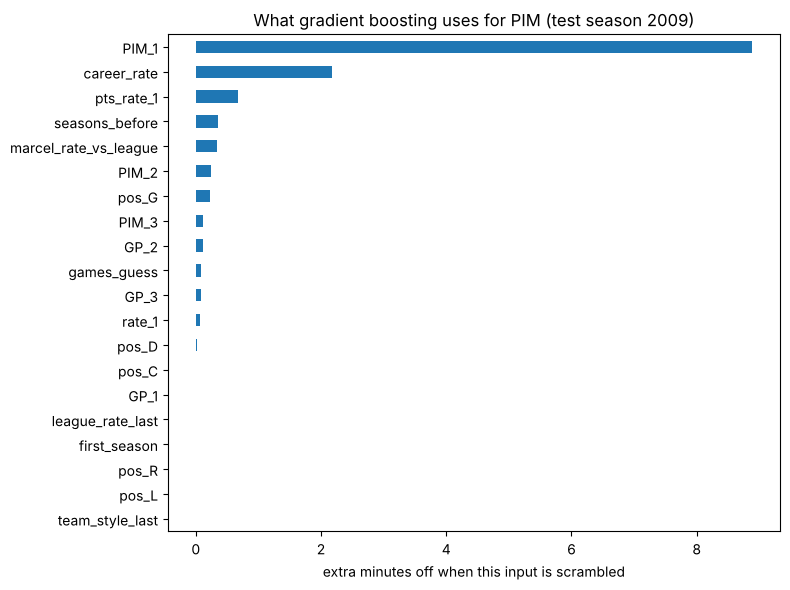

PIM_1                    8.89
career_rate              2.17
pts_rate_1               0.68
seasons_before           0.36
marcel_rate_vs_league    0.34
PIM_2                    0.24
pos_G                    0.23
PIM_3                    0.12
GP_2                     0.11
games_guess              0.09
GP_3                     0.08
rate_1                   0.06
pos_D                    0.03
pos_C                    0.01
GP_1                     0.00
first_season             0.00
pos_R                    0.00
league_rate_last         0.00
pos_L                   -0.00
team_style_last         -0.00
dtype: float64

In [8]:
from sklearn.inspection import permutation_importance
train, test = player_table[player_table["year"] < 2009], player_table[player_table["year"] == 2009]
gb = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_leaf_nodes=15, max_iter=300,
                                   min_samples_leaf=40, random_state=0).fit(train[FEATURES_C], train["PIM"])
imp = permutation_importance(gb, test[FEATURES_C], test["PIM"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=0)
importance_c = pd.Series(imp.importances_mean, index=FEATURES_C).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
importance_c.plot(kind="barh", ax=ax, color="tab:blue")
ax.set(xlabel="extra minutes off when this input is scrambled", title="What gradient boosting uses for PIM (test season 2009)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance_c.png", dpi=150); plt.show()
importance_c.sort_values(ascending=False).round(2)

## What this shows (task c)

- **Gradient boosting is the best: 16.5 minutes off on average, vs 17.2 for Marcel and 18.4 for "same as last season".** It beats Marcel in **9 of 9** test seasons (Wilcoxon p = 0.004): statistically proven.
- The other models (linear, tree, kNN) do **not** beat Marcel. Gradient boosting wins mainly because it is trained on **absolute error**, the same thing MAE measures: it predicts the typical player's PIM instead of being pulled up by the few enforcers.
- **No real overfitting:** gradient boosting's error on its own recent training seasons is 15.4, on new seasons 16.5: a small gap, so it learned a rule that carries over instead of memorising.
- **Last season's PIM** is by far the most used input, then the **career rate**. Points per game helps a little (scorers take fewer penalties). Team style and position add almost nothing once a player's own history is known.
- **The limit is games played:** with this season's real games (not allowed) the error would drop to 14.0. Injuries and players sent down to the minors cannot be known before the season.
- Players in their first NHL season (16%) only get a position-based guess: the biggest weakness, and the place where a better fill could help (data preparation, missing values).